# EE 513 · Assignment 2 Measure Your Camera

**Name:** Andrei Perez **Camera:** iPhone 17 Pro Max, 6.765 mm f/1.78

Predict the spatial resolution of the camera from two measurable numbers, then measure it directly with the slanted-edge method. 

# Setup

In [1]:
import json, datetime, struct
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import cv2
import rawpy
from scipy.optimize import brentq
from scipy.special import erfc

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

ROOT      = Path.cwd()                    
CALIB_DIR = ROOT / "calib_target_img"
EDGE_DIR  = ROOT / "slanted_edge_taget_img"  
CACHE_DIR = ROOT / "_cache";   CACHE_DIR.mkdir(exist_ok=True)
OUT_DIR   = ROOT / "outputs";  OUT_DIR.mkdir(exist_ok=True) 

LAMBDA_UM   = 0.55    
DIAG_35MM   = 43.3     

In [2]:
calib_files = sorted(CALIB_DIR.glob("*.dng"))
edge_files  = sorted(EDGE_DIR.glob("*.dng"))
print(f"Calibration: {len(calib_files)}")
print(f"Slanted-edge: {len(edge_files)}")

Calibration: 19
Slanted-edge: 10


## 0.1 Shared helpers

Made a few helpers for exif extraction, I later realized there was a file on canvas that could have made this work easier

In [3]:
# Found online
_TYPES = {1: ("B", 1), 2: ("s", 1), 3: ("H", 2), 4: ("I", 4), 5: ("II", 8),
          7: ("B", 1), 8: ("h", 2), 9: ("i", 4), 10: ("ii", 8), 11: ("f", 4), 12: ("d", 8)}

_EXIF_TAGS = {
    0x010F: "make", 0x0110: "model",                                
    0x829A: "exposure_s", 0x829D: "N", 0x8827: "iso",                 
    0x920A: "f_mm", 0xA405: "f35_mm", 0xA433: "lens_make", 0xA434: "lens_model",
}
_EXIF_IFD_POINTER = 0x8769


def _read_ifd(fh, offset, endian):
    fh.seek(offset)
    (count,) = struct.unpack(endian + "H", fh.read(2))
    entries = [struct.unpack(endian + "HHII", fh.read(12)) for _ in range(count)]
    out = {}
    for tag, typ, n, value_or_offset in entries:
        if typ not in _TYPES:
            continue
        code, size = _TYPES[typ]
        nbytes = size * n
        if nbytes <= 4:
            raw = struct.pack(endian + "I", value_or_offset)[:nbytes]
        else:
            here = fh.tell(); fh.seek(value_or_offset); raw = fh.read(nbytes); fh.seek(here)
        if typ == 2:
            val = raw.split(b"\x00", 1)[0].decode(errors="replace").strip()
        elif typ in (5, 10): 
            nums = struct.unpack(endian + code[0] * (2 * n), raw)
            vals = [a / b if b else float("nan") for a, b in zip(nums[0::2], nums[1::2])]
            val = vals[0] if n == 1 else tuple(vals)
        else:
            vals = struct.unpack(endian + code * n, raw)
            val = vals[0] if n == 1 else vals
        out[tag] = val
    return out


def dng_exif(path):
    with open(path, "rb") as fh:
        endian = {b"II": "<", b"MM": ">"}[fh.read(2)]
        magic, ifd0 = struct.unpack(endian + "HI", fh.read(6))
        assert magic == 42, "not a TIFF/DNG file"
        tags = _read_ifd(fh, ifd0, endian)
        if _EXIF_IFD_POINTER in tags:
            tags.update(_read_ifd(fh, tags[_EXIF_IFD_POINTER], endian))
    return {name: tags.get(tag) for tag, name in _EXIF_TAGS.items()}

# Found online
def read_exif(path):
    e = dng_exif(path)
    with rawpy.imread(str(path)) as raw:
        H, W = raw.sizes.height, raw.sizes.width    
    return {
        "file":       Path(path).name,
        "make":       e["make"],
        "model":      e["model"],
        "lens_make":  e["lens_make"],
        "lens_model": e["lens_model"],
        "f_mm":       float(e["f_mm"]),
        "f35_mm":     float(e["f35_mm"]),
        "N":          float(e["N"]),
        "iso":        float(e["iso"]),
        "exposure_s": float(e["exposure_s"]),
        "width_px":   W,
        "height_px":  H,
    }

# Helpers I have used in the past for my work
def load_gray(path, cache=True):
    cache_path = CACHE_DIR / (Path(path).stem + "_gray.png")
    if cache and cache_path.exists():
        return cv2.imread(str(cache_path), cv2.IMREAD_GRAYSCALE)
    with rawpy.imread(str(path)) as raw:
        rgb = raw.postprocess(use_camera_wb=True, no_auto_bright=False, output_bps=8, user_flip=0)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    if cache:
        cv2.imwrite(str(cache_path), gray)
    return gray


def load_preview(path, half=True):
    with rawpy.imread(str(path)) as raw:
        return raw.postprocess(use_camera_wb=True, half_size=half, output_bps=8, user_flip=0)


def bayer_layout(path):
    with rawpy.imread(str(path)) as raw:
        desc = raw.color_desc.decode()
        return [[desc[i] for i in row] for row in raw.raw_pattern.tolist()]


def green_plane(path, which=0):
    with rawpy.imread(str(path)) as raw:
        bayer   = raw.raw_image_visible.astype(np.float64)
        pattern = raw.raw_pattern
        desc    = raw.color_desc.decode()
        blacks  = raw.black_level_per_channel
        white   = float(raw.white_level)
    greens = [(r, c) for r in range(2) for c in range(2) if desc[pattern[r, c]] == "G"]
    r0, c0 = greens[which]
    black = float(blacks[pattern[r0, c0]])
    plane = (bayer[r0::2, c0::2] - black) / (white - black)
    info = {"site": (r0, c0), "black": black, "white": white,
            "layout": bayer_layout(path), "shape": plane.shape}
    return plane, info

In [4]:
exif0 = read_exif(edge_files[0])
for k, v in exif0.items():
    print(f"{k:12s} {v}")
print("CFA layout:", bayer_layout(edge_files[0]))

F_MM   = exif0["f_mm"]      
F35_MM = exif0["f35_mm"]    
N      = exif0["N"]         # F NUMBER!!
IMG_W, IMG_H = exif0["width_px"], exif0["height_px"]

_cal_exif = {(e["model"], e["lens_model"], round(e["f_mm"], 3), round(e["N"], 2)) for e in map(read_exif, calib_files)}
print("Calibration captures, distinct camera/lens settings:", _cal_exif)

file         slanted_edge001.dng
make         Apple
model        iPhone 17 Pro Max
lens_make    Apple
lens_model   iPhone 17 Pro Max back camera 6.765mm f/1.78
f_mm         6.764999865652793
f35_mm       24.0
N            1.8
iso          200.0
exposure_s   0.008333333333333333
width_px     4032
height_px    3024
CFA layout: [['B', 'G'], ['G', 'R']]
Calibration captures, distinct camera/lens settings: {('iPhone 17 Pro Max', 'iPhone 17 Pro Max back camera 6.765mm f/1.78', 6.765, 1.8)}


# Part 1 · Camera Geometry

## Item 1 · Calibrate with cv2.calibrateCamera

**Task.** Calibrate from ≥ 15 successful checkerboard detections using the square size measured in Exercise 1. 

**Deliverable.** Labeled list of calibration parameters with units.


In [5]:
BOARD_INNER = (9, 6)         
SQUARE_MM   = 20.0          
SB_FLAGS = cv2.CALIB_CB_NORMALIZE_IMAGE | cv2.CALIB_CB_EXHAUSTIVE | cv2.CALIB_CB_ACCURACY


def detect_corners(gray, board=BOARD_INNER):
    ok, corners = cv2.findChessboardCornersSB(gray, board, flags=SB_FLAGS)
    return corners.astype(np.float32) if ok else None


objp = np.zeros((BOARD_INNER[0] * BOARD_INNER[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:BOARD_INNER[0], 0:BOARD_INNER[1]].T.reshape(-1, 2) * SQUARE_MM

CORNER_CACHE = CACHE_DIR / "corners_9x6.npz"
if CORNER_CACHE.exists():
    _c = np.load(CORNER_CACHE, allow_pickle=True)
    detections = dict(zip(_c["files"].tolist(), list(_c["corners"])))
else:
    detections = {}
    for f in calib_files:
        corners = detect_corners(load_gray(f))
        if corners is not None:
            detections[f.name] = corners
        print(f"{f.name}: {'found' if corners is not None else 'NOT found'}")
    np.savez(CORNER_CACHE, files=np.array(list(detections)), corners=np.array(list(detections.values())))

used_files    = [CALIB_DIR / n for n in detections]
image_points  = [detections[f.name] for f in used_files]
object_points = [objp] * len(image_points)
print(f"Successful detections: {len(used_files)} / {len(calib_files)}  (need ≥ 15)")
assert len(used_files) >= 15 # Created this test since I wasnt getting values which made sense

Successful detections: 17 / 19  (need ≥ 15)


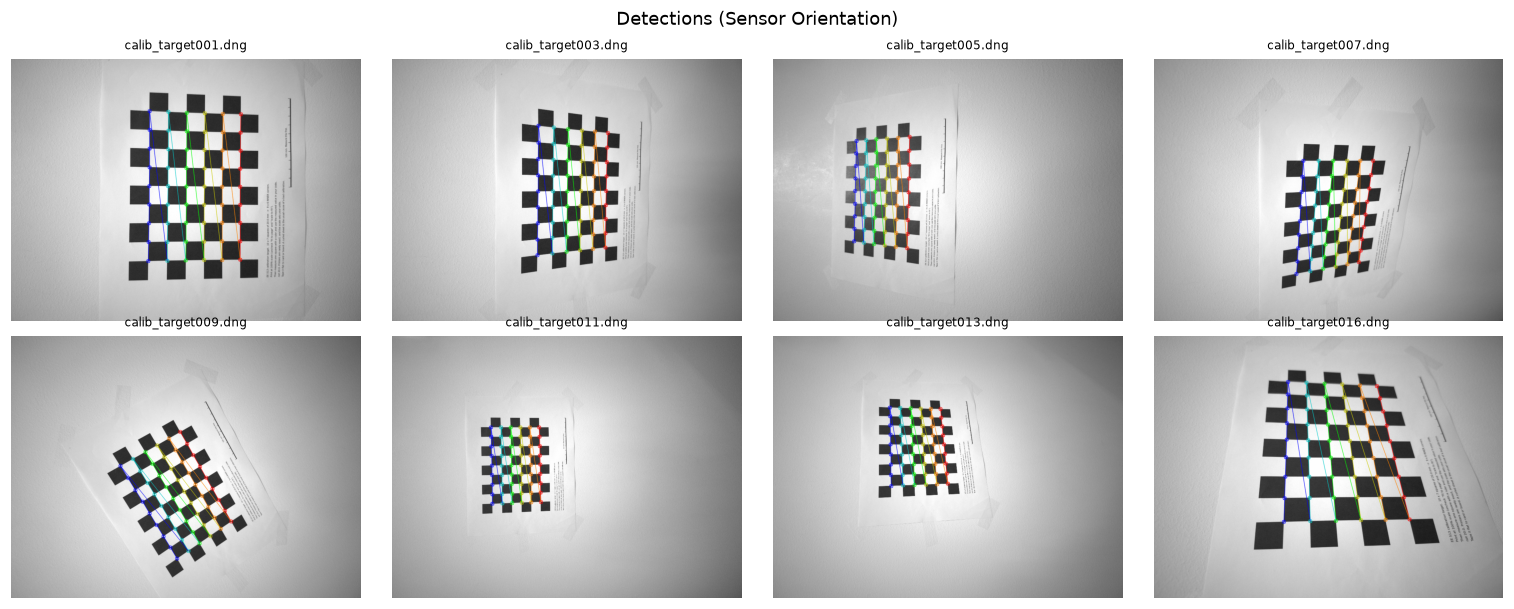

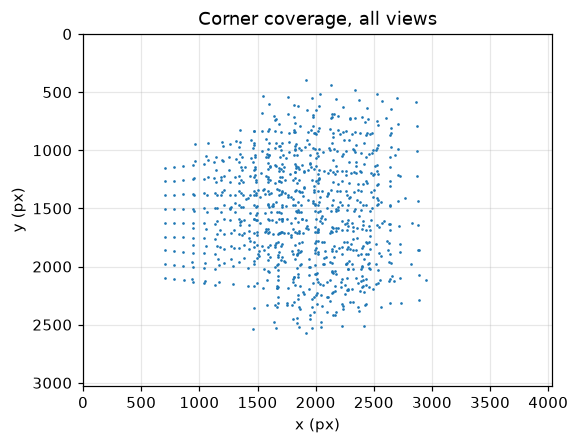

In [6]:
show = used_files[::max(1, len(used_files) // 8)][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 5.6))
for ax, f in zip(axes.ravel(), show):
    small = cv2.cvtColor(cv2.resize(load_gray(f), None, fx=0.25, fy=0.25), cv2.COLOR_GRAY2BGR)
    cv2.drawChessboardCorners(small, BOARD_INNER, detections[f.name] * 0.25, True)
    ax.imshow(small[..., ::-1]); ax.set_title(f.name, fontsize=8); ax.axis("off")
for ax in axes.ravel()[len(show):]:
    ax.axis("off")
fig.suptitle("Detections (Sensor Orientation)"); fig.tight_layout(); plt.show()


# Wanted to use this to make sense on what was detected, AI generated
allpts = np.concatenate([c.reshape(-1, 2) for c in image_points])
fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.plot(allpts[:, 0], allpts[:, 1], ".", ms=1.5)
ax.set(xlim=(0, IMG_W), ylim=(IMG_H, 0), aspect="equal", title="Corner coverage, all views", xlabel="x (px)", ylabel="y (px)")
plt.show()

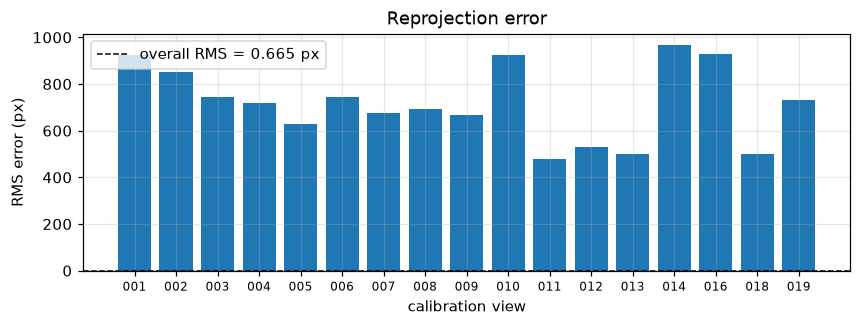

In [7]:
rms, K, dist, rvecs, tvecs = cv2.calibrateCamera(
    object_points, image_points, (IMG_W, IMG_H), None, None, flags=cv2.CALIB_FIX_K3)

per_view = []
for objp_i, imgp, rv, tv in zip(object_points, image_points, rvecs, tvecs):
    proj, _ = cv2.projectPoints(objp_i, rv, tv, K, dist)
    per_view.append(np.sqrt(np.mean(np.sum((proj - imgp) ** 2, axis=2))))
per_view = np.array(per_view)

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.bar(range(len(per_view)), per_view)
ax.axhline(rms, ls="--", c="k", lw=1, label=f"overall RMS = {rms:.3f} px")
ax.set_xticks(range(len(per_view)), [f.stem[-3:] for f in used_files], fontsize=8)
ax.set(xlabel="calibration view", ylabel="RMS error (px)", title="Reprojection error"); ax.legend()
plt.show()

In [8]:
def pitch_from_exif(f_mm=F_MM, f35_mm=F35_MM, w=IMG_W, h=IMG_H):
    crop = f35_mm / f_mm
    diag_mm = DIAG_35MM / crop
    return 1000 * diag_mm / np.hypot(w, h), crop, diag_mm


def report_calibration(K, dist, rms, pitch_um=None):
    fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]
    k1, k2, p1, p2 = dist.ravel()[:4]
    rows = [("f_x", f"{fx:.2f} px"), ("f_y", f"{fy:.2f} px")]
    if pitch_um is not None:
        rows += [("f_x", f"{fx * pitch_um / 1000:.4f} mm"), ("f_y", f"{fy * pitch_um / 1000:.4f} mm")]
    rows += [("c_x", f"{cx:.2f} px   (image centre {IMG_W / 2:.1f})"), ("c_y", f"{cy:.2f} px   (image centre {IMG_H / 2:.1f})"),
             ("k1", f"{k1:+.5f} (dimensionless)"), ("k2", f"{k2:+.5f} (dimensionless)"),
             ("p1", f"{p1:+.6f} (dimensionless)"), ("p2", f"{p2:+.6f} (dimensionless)"),
             ("RMS reprojection error", f"{rms:.3f} px")]
    for name, val in rows:
        print(f"  {name:24s} {val}")

p_exif_um, _, _ = pitch_from_exif()
print(f"Calibration from {len(used_files)} views, image {IMG_W} × {IMG_H} px, square {SQUARE_MM} mm ")
report_calibration(K, dist, rms, pitch_um=p_exif_um)

np.savez(OUT_DIR / "calibration.npz", K=K, dist=dist, rms=rms, image_size=(IMG_W, IMG_H),
         board_inner=BOARD_INNER, square_mm=SQUARE_MM, files=[f.name for f in used_files])

Calibration from 17 views, image 4032 × 3024 px, square 20.0 mm 
  f_x                      2924.77 px
  f_y                      2927.41 px
  f_x                      7.0828 mm
  f_y                      7.0892 mm
  c_x                      2024.14 px   (image centre 2016.0)
  c_y                      1513.48 px   (image centre 1512.0)
  k1                       +0.18172 (dimensionless)
  k2                       -0.52233 (dimensionless)
  p1                       -0.002338 (dimensionless)
  p2                       -0.000750 (dimensionless)
  RMS reprojection error   0.665 px


> **Answer**
>
> Calibration from 17 of 19 views. Found that `calib_target015` and `017` were not detected. 9 × 6 inner corners, 20.0 mm squares:
>
> | Parameter | Value |
> |---|---|
> | $f_x$ | 2924.77 px = 7.083 mm |
> | $f_y$ | 2927.41 px = 7.089 mm |
> | $c_x$ | 2024.14 px (image centre 2016.0) |
> | $c_y$ | 1513.48 px (image centre 1512.0) |
> | $k_1$ | +0.1817 (dimensionless) |
> | $k_2$ | −0.5223 (dimensionless) |
> | $p_1$ | −0.00234 (dimensionless) |
> | $p_2$ | −0.00075 (dimensionless) |
> | RMS error | **0.665 px** |
>
> The RMS is below the one pixel threshold, so the target was flat enough.

## Item 2 · Undistort an image with a long straight edge near the frame boundary

**Task.** Undistort an image with a long straight edge near the edge of the frame, where distortion is largest.

**Deliverable.** Original and undistorted images, side by side.

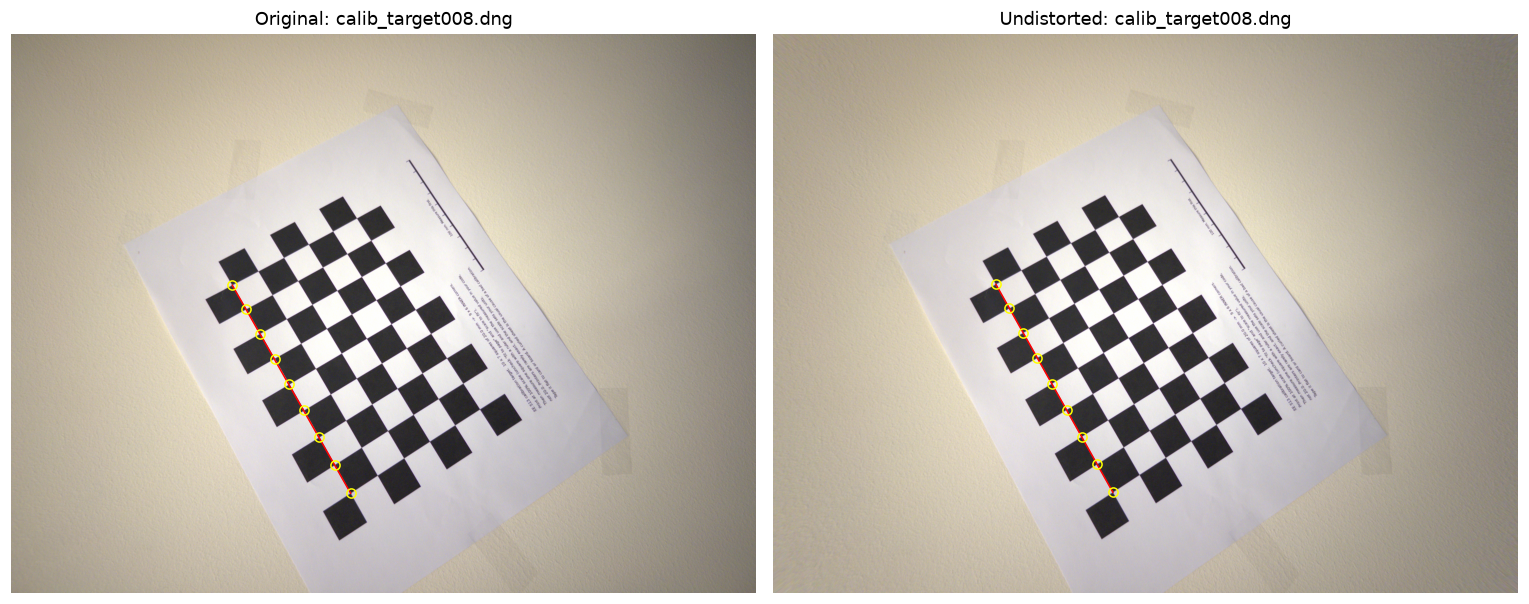

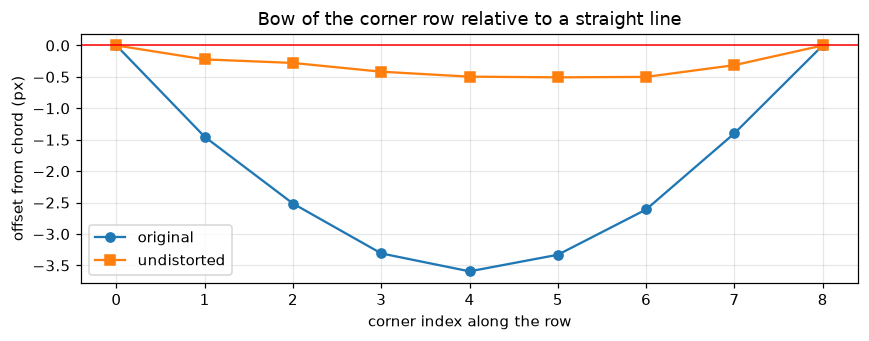

Row used: 5 (0-based) of 6; its midpoint is 646 px from the principal point


In [9]:
UNDISTORT_FILE = CALIB_DIR / "calib_target008.dng"

img = load_preview(UNDISTORT_FILE, half=False)
newK, valid_roi = cv2.getOptimalNewCameraMatrix(K, dist, (IMG_W, IMG_H), alpha=0)  
und = cv2.undistort(img, K, dist, None, newK)

c_orig = detections[UNDISTORT_FILE.name].reshape(BOARD_INNER[1], BOARD_INNER[0], 2)
pp = np.array([K[0, 2], K[1, 2]])
EDGE_ROW = int(np.argmax([np.linalg.norm(r.mean(0) - pp) for r in c_orig]))
row_orig = c_orig[EDGE_ROW]
row_und = cv2.undistortPoints(row_orig.reshape(-1, 1, 2), K, dist, P=newK).reshape(-1, 2)

def offsets_from_chord(pts):
    a, b = pts[0], pts[-1]
    n = np.array([-(b - a)[1], (b - a)[0]]) / np.linalg.norm(b - a)
    return (pts - a) @ n

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
for ax, (im, pts, title) in zip(axes, [(img, row_orig, "Original"), (und, row_und, "Undistorted")]):
    ax.imshow(im); ax.plot(pts[[0, -1], 0], pts[[0, -1], 1], "r-", lw=1)
    ax.plot(pts[:, 0], pts[:, 1], "o", mfc="none", mec="yellow", ms=6)
    ax.set_title(f"{title}: {UNDISTORT_FILE.name}"); ax.axis("off")
fig.tight_layout(); fig.savefig(OUT_DIR / "item02_undistort.png", bbox_inches="tight", dpi=110); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(offsets_from_chord(row_orig), "o-", label="original")
ax.plot(offsets_from_chord(row_und), "s-", label="undistorted")
ax.axhline(0, c="r", lw=1)
ax.set(xlabel="corner index along the row", ylabel="offset from chord (px)",
       title="Bow of the corner row relative to a straight line")
ax.legend(); fig.tight_layout(); fig.savefig(OUT_DIR / "item02_row_bow.png", bbox_inches="tight"); plt.show()
print(f"Row used: {EDGE_ROW} (0-based) of {BOARD_INNER[1]}; its midpoint is "
      f"{np.linalg.norm(row_orig.mean(0) - pp):.0f} px from the principal point")

> **Answer**
>
> `calib_target008`. The figure marks the corner row farthest from the principal point, 646 px from it. In the original, the middle of the row goes to 3.5 px away from the chord. After undistortion the corners stay **within ±0.6 px** of it, which is about the corner-localisation noise. Ran a few tests and the most distorted row across all views (`calib_target014`) reaches 3.0 px.

## Item 3 · Quantify the correction (straightness of one corner row)

**Task.** Fit a straight line through one row of detected corners. Report the maximum perpendicular deviation of the corners from the fitted line, in pixels, before and after undistortion.

**Deliverable.** Two deviation values in pixels.

In [10]:
def max_perp_deviation(pts):
    pts = np.asarray(pts, float).reshape(-1, 2)
    centred = pts - pts.mean(axis=0)
    _, _, vt = np.linalg.svd(centred, full_matrices=False)
    normal = vt[1]                     
    return float(np.max(np.abs(centred @ normal)))


def undistort_pts(pts):
    return cv2.undistortPoints(np.asarray(pts, np.float32).reshape(-1, 1, 2), K, dist, P=K).reshape(-1, 2)


ITEM3_VIEW = UNDISTORT_FILE.name
ITEM3_ROW  = EDGE_ROW
row_pts = detections[ITEM3_VIEW].reshape(BOARD_INNER[1], BOARD_INNER[0], 2)[ITEM3_ROW]

dev_before = max_perp_deviation(row_pts)
dev_after  = max_perp_deviation(undistort_pts(row_pts))
print(f"{ITEM3_VIEW}, row {ITEM3_ROW}:")
print(f"Max perpendicular deviation  before: {dev_before:.3f} px   after: {dev_after:.3f} px")

tab = []
for f in used_files:
    rows_ = detections[f.name].reshape(BOARD_INNER[1], BOARD_INNER[0], 2)
    for r_i, r in enumerate(rows_):
        tab.append((f.name, r_i, max_perp_deviation(r), max_perp_deviation(undistort_pts(r))))
tab_b = np.array([t[2] for t in tab]); tab_a = np.array([t[3] for t in tab])
worst = int(np.argmax(tab_b))
print(f"\nBefore median {np.median(tab_b):.3f} px, max {tab_b.max():.3f} px "
      f"({tab[worst][0]} row {tab[worst][1]});  after median {np.median(tab_a):.3f} px, max {tab_a.max():.3f} px")

calib_target008.dng, row 5:
Max perpendicular deviation  before: 2.070 px   after: 0.351 px

Before median 1.148 px, max 3.011 px (calib_target014.dng row 2);  after median 0.319 px, max 1.878 px


> **Answer**
>
>
> **Before undistortion: 2.070 px**
> **After undistortion: 0.351 px**
>
> The remaining 0.45 px is consistent with the 0.67 px RMS reprojection error, which comes from corner noise and the sheet not being perfectly flat. In all the 102 rows in the 17 views the median falls from 1.15 px to 0.32 px.

## Item 4 · Pixel pitch, two independent routes

Compute your pixel pitch in micrometers as 1000 fmm / fpx, where fmm is the focal length recorded in the EXIF metadata and fpx is the mean of the two focal lengths in pixels from item 1. Then obtain it a second way, by a route that does not use your calibration at all: divide the 35 mm equivalent focal length in the EXIF by the actual focal length to get the crop factor, divide the 43.3 mm diagonal of 35 mm film by the crop factor to get your sensor diagonal, and divide that by the image diagonal in pixels. Everything in Part 2 rests on this number, and the second route is the only warning you will get that the first one is wrong.

**Deliverable.** Both pitches in µm, their % difference, and which one Part 2 will use and why (2–3 sentences).

In [11]:
# Route A: from calibration
f_px_mean = (K[0, 0] + K[1, 1]) / 2
p_A_um    = 1000 * F_MM / f_px_mean

# Route B: from EXIF 
p_B_um, crop_factor, sensor_diag_mm = pitch_from_exif()
img_diag_px = np.hypot(IMG_W, IMG_H)
p_B_lo, _, _ = pitch_from_exif(f35_mm=F35_MM - 0.5)     
p_B_hi, _, _ = pitch_from_exif(f35_mm=F35_MM + 0.5)

pct_diff = 100 * (p_A_um - p_B_um) / p_B_um             
print(f"Route A (calibration): f_px = {f_px_mean:.2f} px → p = {p_A_um:.4f} µm")
print(f"Route B (EXIF/crop)  : crop {crop_factor:.4f}, sensor diag {sensor_diag_mm:.3f} mm, "
      f"image diag {img_diag_px:.1f} px → p = {p_B_um:.4f} µm")
print(f"                       (35 mm-eq. rounding band 23.5–24.5 mm → {p_B_hi:.4f}–{p_B_lo:.4f} µm)")
print(f"Difference (A − B)/B : {pct_diff:+.2f} %")

board_z_mm = np.array([t[2, 0] for t in tvecs])
s_img_mm = F_MM * np.median(board_z_mm) / (np.median(board_z_mm) - F_MM)
p_A_corr_um = 1000 * s_img_mm / f_px_mean
print(f"\nCalibration board distance: median {np.median(board_z_mm):.0f} mm (range {board_z_mm.min():.0f}–{board_z_mm.max():.0f} mm)")
print(f"Lens-to-sensor distance at that range: s' = {s_img_mm:.3f} mm (vs f = {F_MM:.3f} mm, +{100 * (s_img_mm / F_MM - 1):.1f} %)")
print(f"Route A with s' in place of f: p = {p_A_corr_um:.4f} µm → difference from route B {100 * (p_A_corr_um - p_B_um) / p_B_um:+.2f} %")

P_UM = p_B_um                 
print(f"\nPitch used in Part 2: p = {P_UM:.4f} µm")

Route A (calibration): f_px = 2926.09 px → p = 2.3120 µm
Route B (EXIF/crop)  : crop 3.5477, sensor diag 12.205 mm, image diag 5040.0 px → p = 2.4217 µm
                       (35 mm-eq. rounding band 23.5–24.5 mm → 2.3722–2.4732 µm)
Difference (A − B)/B : -4.53 %

Calibration board distance: median 359 mm (range 272–550 mm)
Lens-to-sensor distance at that range: s' = 6.895 mm (vs f = 6.765 mm, +1.9 %)
Route A with s' in place of f: p = 2.3563 µm → difference from route B -2.70 %

Pitch used in Part 2: p = 2.4217 µm


> **Answer**
>
> **Route A (calibration): p = 2.312 µm** ($f_\text{px}$ = 2926.1 px, $f_\text{mm}$ = 6.765 mm)
> **Route B (EXIF crop factor): p = 2.422 µm** (crop 3.548, sensor diagonal 12.21 mm, image diagonal 5040 px)
> **Difference: −4.5 %** (A relative to B)
>
> I think Part 2 uses route B 2.422 µm. The 4.5 % gap is larger than route B's only uncertainty. Route B does not depend on focus distance, so it is the safer basis for the predictions.

<a id="part2"></a>
# Part 2 · Predicted Response

$\lambda = 0.55$ µm, $N$ from EXIF, $p$ from item 4. All frequencies in cycles/µm.

I will use np.sinc

In [12]:
def mtf_diffraction(nu, nu_c):
    s = np.clip(np.asarray(nu, float) / nu_c, 0.0, 1.0)
    return (2 / np.pi) * (np.arccos(s) - s * np.sqrt(1 - s ** 2))


def mtf_pixel(nu, p_um):
    return np.abs(np.sinc(np.asarray(nu, float) * p_um))


def mtf_pred(nu, nu_c, p_um):
    return mtf_diffraction(nu, nu_c) * mtf_pixel(nu, p_um)

## Item 5 · Diffraction cutoff, green-plane Nyquist, and their ratio

**Deliverable.** Three values, each in cycles/µm and cycles/mm.

In [13]:
nu_c      = 1 / (LAMBDA_UM * N)
nu_nyq_g  = 1 / (4 * P_UM)
nu_nyq_full = 1 / (2 * P_UM)
ratio     = nu_c / nu_nyq_g

for name, v in [("Diffraction cutoff ν_c", nu_c), ("Green-plane Nyquist", nu_nyq_g)]:
    print(f"{name:24s} {v:.4f} cyc/µm   {v * 1000:.1f} cyc/mm")
print(f"{'Ratio ν_c / ν_Nyq,g':24s} {ratio:.3f}  (dimensionless: identical in cyc/µm and cyc/mm)")
print(f"\n(for reference) full-sensor Nyquist 1/(2p) = {nu_nyq_full:.4f} cyc/µm = {nu_nyq_full * 1000:.1f} cyc/mm")

Diffraction cutoff ν_c   1.0101 cyc/µm   1010.1 cyc/mm
Green-plane Nyquist      0.1032 cyc/µm   103.2 cyc/mm
Ratio ν_c / ν_Nyq,g      9.785  (dimensionless: identical in cyc/µm and cyc/mm)

(for reference) full-sensor Nyquist 1/(2p) = 0.2065 cyc/µm = 206.5 cyc/mm


> **Answer**
>
> | Quantity | cycles/µm | cycles/mm |
> |---|---|---|
> | Diffraction cutoff  | **1.0101** | **1010.1** |
> | Green-plane Nyquist  | **0.1032** | **103.2** |
> | Ratio | **9.78** | 9.78  |

## Item 6 · Binding limit and crossover f-number

**Task.** State whether diffraction or sampling is the binding limit for your camera, and find the f-number at which that answer would change by setting the diffraction cutoff equal to the full-sensor Nyquist frequency 1/(2p) and solving for N.

**Deliverable.** Crossover $N$ and a 2–4 sentence explanation.

In [14]:
N_cross = 2 * P_UM / LAMBDA_UM
print(f"Camera N = {N:.2f},  crossover N = {N_cross:.2f}")
print(f"At N = {N:.2f}: ν_c = {nu_c:.3f} cyc/µm vs full-sensor Nyquist {nu_nyq_full:.3f} cyc/µm "
      f"→ {'sampling' if nu_c > nu_nyq_full else 'diffraction'} is the binding limit")

Camera N = 1.80,  crossover N = 8.81
At N = 1.80: ν_c = 1.010 cyc/µm vs full-sensor Nyquist 0.206 cyc/µm → sampling is the binding limit


> **Answer**
>
> **Crossover f-number = 8.81.** At f/1.8 sampling would be the binding limit. The diffraction cutoff (1.01 cyc/µm) is 4.9× the full-sensor Nyquist frequency and 9.8× the green plane Nyquist frequency.

## Item 7 · Plot the predicted MTF

**Task.** Plot MTFd(ν), MTFp(ν), and their product from zero to νc, with a vertical line marking the green-plane Nyquist frequency. Report the value of the product at that frequency.

**Deliverable.** Figure, and predicted modulation at Nyquist.

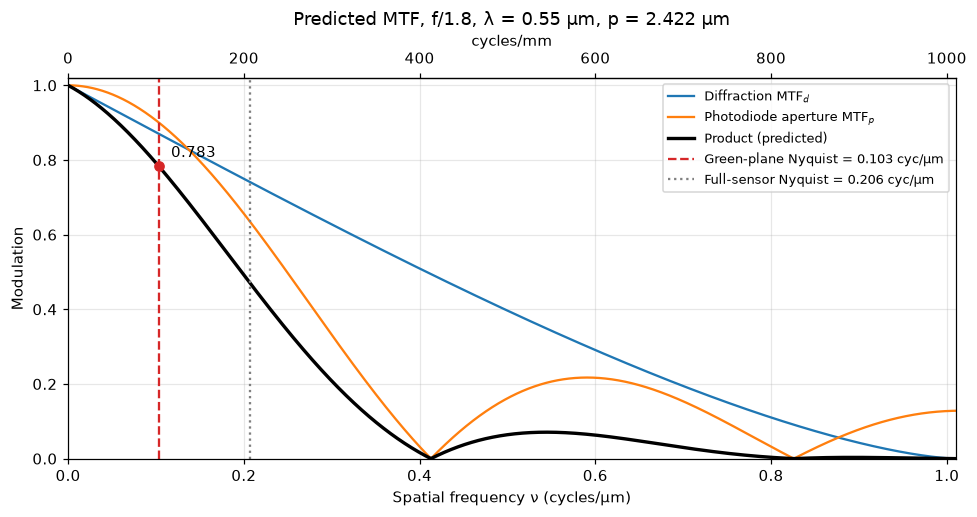

Predicted modulation at green-plane Nyquist: 0.7834  (diffraction 0.8701 × aperture 0.9003)


In [15]:
nu = np.linspace(0, nu_c, 4000)
mtf_at_nyq_pred = float(mtf_pred(nu_nyq_g, nu_c, P_UM))

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(nu, mtf_diffraction(nu, nu_c), label=r"Diffraction $\mathrm{MTF}_d$")
ax.plot(nu, mtf_pixel(nu, P_UM), label=r"Photodiode aperture $\mathrm{MTF}_p$")
ax.plot(nu, mtf_pred(nu, nu_c, P_UM), lw=2.2, c="k", label="Product (predicted)")
ax.axvline(nu_nyq_g, ls="--", c="tab:red", label=f"Green-plane Nyquist = {nu_nyq_g:.3f} cyc/µm")
ax.axvline(nu_nyq_full, ls=":", c="gray", label=f"Full-sensor Nyquist = {nu_nyq_full:.3f} cyc/µm")
ax.plot(nu_nyq_g, mtf_at_nyq_pred, "o", c="tab:red")
ax.annotate(f"{mtf_at_nyq_pred:.3f}", (nu_nyq_g, mtf_at_nyq_pred), xytext=(8, 6), textcoords="offset points")
ax.set(xlim=(0, nu_c), ylim=(0, 1.02), xlabel="Spatial frequency ν (cycles/µm)", ylabel="Modulation",
       title=f"Predicted MTF, f/{N:.1f}, λ = {LAMBDA_UM} µm, p = {P_UM:.3f} µm")
sec = ax.secondary_xaxis("top", functions=(lambda v: v * 1000, lambda v: v / 1000)); sec.set_xlabel("cycles/mm")
ax.legend(fontsize=8.5)
fig.tight_layout(); fig.savefig(OUT_DIR / "item07_predicted_mtf.png", bbox_inches="tight"); plt.show()

print(f"Predicted modulation at green-plane Nyquist: {mtf_at_nyq_pred:.4f}  "
      f"(diffraction {float(mtf_diffraction(nu_nyq_g, nu_c)):.4f} × aperture {float(mtf_pixel(nu_nyq_g, P_UM)):.4f})")

> **Answer**
>
> **Predicted modulation =  0.783** 

## Item 8 · Predicted MTF50

**Task.** Determine the frequency at which the predicted response falls to 0.5, which is your predicted MTF50. If it lies above the Nyquist frequency, explain what that implies about aliasing and about which physical effect will actually set the MTF50 you measure in Part 4.

**Deliverable.** Predicted MTF50 in cycles/µm and explanation

In [16]:
mtf50_pred = brentq(lambda v: mtf_pred(v, nu_c, P_UM) - 0.5, 1e-6, min(nu_c, 1 / P_UM) * 0.999)
print(f"Predicted MTF50 = {mtf50_pred:.4f} cyc/µm  ({mtf50_pred * 1000:.1f} cyc/mm)")
print(f"  = {mtf50_pred * 2 * P_UM:.4f} cycles per green-plane pixel")
print(f"  relative to green-plane Nyquist: {mtf50_pred / nu_nyq_g:.2f}×")

# Personal use

#print(f"  (diffraction alone would reach 0.5 at "
      #f"{brentq(lambda v: mtf_diffraction(v, nu_c) - 0.5, 1e-6, nu_c * 0.999):.3f} cyc/µm; "
      #f"the aperture alone at {brentq(lambda v: mtf_pixel(v, P_UM) - 0.5, 1e-6, 1 / P_UM * 0.999):.3f} cyc/µm)")


Predicted MTF50 = 0.1974 cyc/µm  (197.4 cyc/mm)
  = 0.9562 cycles per green-plane pixel
  relative to green-plane Nyquist: 1.91×


> **Answer**
>
> **Predicted MTF50 = 0.197 cyc/µm**. In the green plane pixel it would be 0.96 cycles per green-plane pixel, so almost 1.9× the green-plane Nyquist frequency. Because the predicted response stays above 50 % beyond Nyquist and the model has no optical low-pass filter, any scene detail between 0.10 and roughly 0.4 cyc/µm would be passed with high contrast and **alias** into false low-frequency patterns.The slanted edge projection supersamples the edge, so Nyquist does not cap the measured MTF50. The measured value will then be set by the pixel aperture plus any blur the model doesnt detect like lens aberrations and defocus.

### Freezing predictions for better analysis


In [17]:
PRED_FILE = OUT_DIR / "predictions_frozen.json"
predictions = {
    "frozen_at": datetime.datetime.now().isoformat(timespec="seconds"),
    "N": N, "lambda_um": LAMBDA_UM, "p_um": float(P_UM),
    "nu_c_cyc_per_um": float(nu_c), "nu_nyq_green_cyc_per_um": float(nu_nyq_g), "ratio": float(ratio),
    "N_crossover": float(N_cross), "mtf_at_nyq_pred": float(mtf_at_nyq_pred), "mtf50_pred_cyc_per_um": float(mtf50_pred),
}
if PRED_FILE.exists():
    print("Predictions")
    predictions = json.loads(PRED_FILE.read_text())
elif any(np.isnan(v) for v in predictions.values() if isinstance(v, float)):
    print("Not frozen: some predicted values are still NaN.")
else:
    PRED_FILE.write_text(json.dumps(predictions, indent=2))
    print("Frozen →", PRED_FILE)
print(json.dumps(predictions, indent=2))

Predictions
{
  "frozen_at": "2026-10-13T23:17:50",
  "N": 1.8,
  "lambda_um": 0.55,
  "p_um": 2.4216641384157236,
  "nu_c_cyc_per_um": 1.01010101010101,
  "nu_nyq_green_cyc_per_um": 0.10323479463322789,
  "ratio": 9.784501569356458,
  "N_crossover": 8.806051412420812,
  "mtf_at_nyq_pred": 0.783364054891017,
  "mtf50_pred_cyc_per_um": 0.19741715670353735
}


# Part 3 · Validating the Measurement

In [18]:
SIGMA_PX  = 1.0
EDGE_DEG  = 5.0

def analytic_mtf50(sigma):
    return np.sqrt(np.log(2) / (2 * np.pi ** 2 * sigma ** 2))

print(f"Analytic MTF50 for σ = {SIGMA_PX}: {analytic_mtf50(SIGMA_PX):.4f} cycles/pixel")

Analytic MTF50 for σ = 1.0: 0.1874 cycles/pixel


## Item 9 · Synthetic slanted edge

**Task.** Generate a synthetic slanted edge by tilting a step edge 5 degrees, convolving it with a Gaussian point spread function of standard deviation 1.0 pixel, and sampling the result on a pixel grid.

**Deliverable.** Image of the simulated capture.

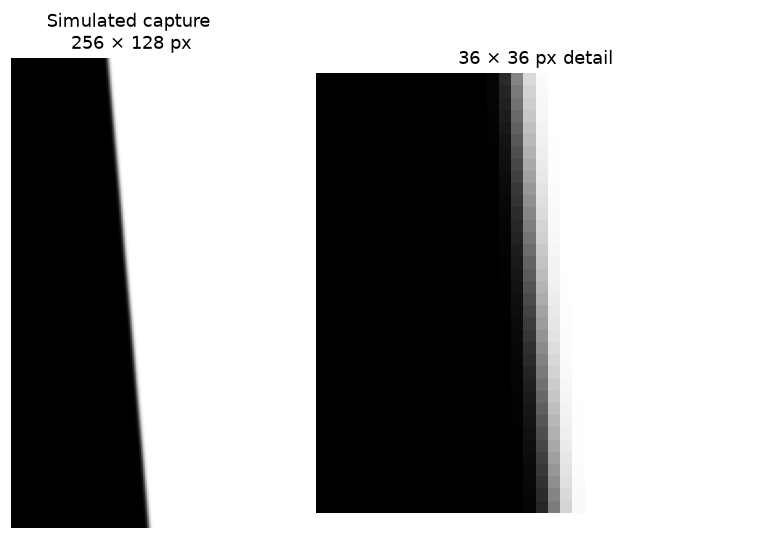

In [19]:
def synthetic_edge(h=256, w=128, angle_deg=EDGE_DEG, sigma=SIGMA_PX, lo=0.05, hi=0.30, noise=0.0, seed=0, shot=None):
    y, x = np.mgrid[0:h, 0:w].astype(float)
    th = np.deg2rad(angle_deg)
    x_edge = (w - 1) / 2 + (y - (h - 1) / 2) * np.tan(th)  
    d = (x - x_edge) * np.cos(th)                             
    img = lo + (hi - lo) * 0.5 * erfc(-d / (sigma * np.sqrt(2)))
    rng = np.random.default_rng(seed)
    if noise:
        img = img + rng.normal(0, noise, img.shape)
    if shot is not None:                      
        a, b = shot
        img = img + rng.normal(0, 1, img.shape) * np.sqrt(a * np.clip(img, 0, None) + b)
    return img

sim = synthetic_edge()

fig, axes = plt.subplots(1, 2, figsize=(8, 5), gridspec_kw={"width_ratios": [1, 1]})
axes[0].imshow(sim, cmap="gray"); axes[0].set_title(f"Simulated capture\n 256 × 128 px"); axes[0].axis("off")
axes[1].imshow(sim[110:146, 46:82], cmap="gray", interpolation="nearest"); axes[1].set_title("36 × 36 px detail"); axes[1].axis("off")
fig.tight_layout(); fig.savefig(OUT_DIR / "item09_sim_edge.png", bbox_inches="tight"); plt.show()

## Item 10 · Measure the simulated edge with the real-data code

**Task.** Run function that will be used on the real captures.

**Deliverable.** ESF, LSF, and MTF figures.

Fitted edge angle: 5.000° (true 5.0°)


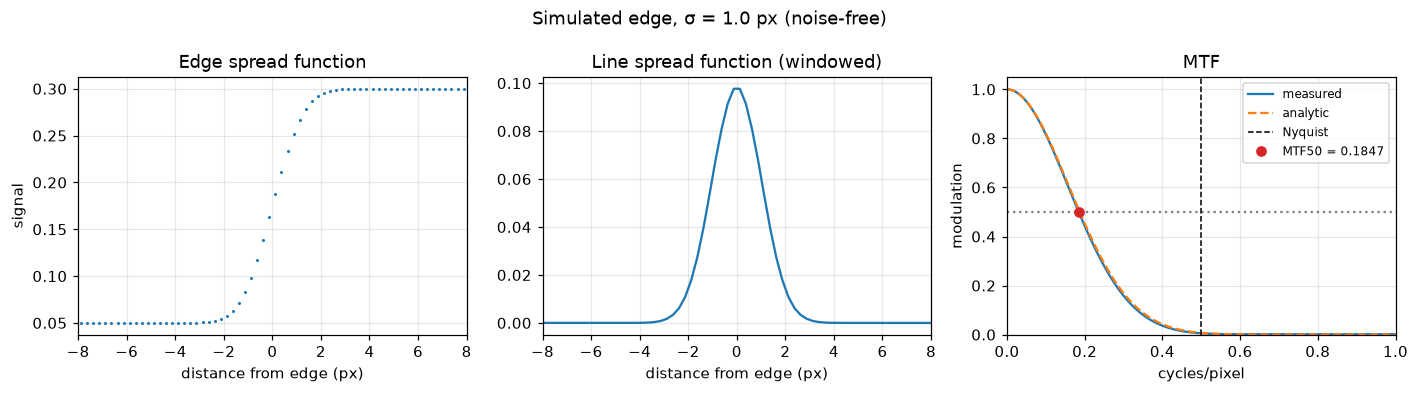

In [20]:
def edge_centroids(roi, window=8.0, smooth=1.5):
    roi = np.asarray(roi, dtype=float)
    smoothed = cv2.GaussianBlur(roi, (0, 0), sigmaX=smooth, sigmaY=0.01)
    coarse = np.argmax(np.abs(np.diff(smoothed, axis=1)), axis=1) + 0.5
    deriv = np.abs(np.diff(roi, axis=1))
    x = np.arange(deriv.shape[1]) + 0.5
    weight = np.where(np.abs(x[None, :] - coarse[:, None]) <= window, deriv, 0.0)
    total = weight.sum(axis=1)
    centers = np.full(roi.shape[0], np.nan)
    good = total > 1e-12
    centers[good] = (weight[good] * x).sum(axis=1) / total[good]
    return centers


def fit_edge_line(centers):
    rows = np.arange(len(centers)); ok = np.isfinite(centers)
    slope, intercept = np.polyfit(rows[ok], centers[ok], 1)
    resid = centers - (slope * rows + intercept)
    ok &= np.abs(resid) < 3 * np.nanstd(resid[ok]) + 1e-9         
    slope, intercept = np.polyfit(rows[ok], centers[ok], 1)
    return slope, intercept


def slanted_edge_mtf(roi, bin_width=0.25, window=8.0):
    roi = np.asarray(roi, dtype=float)
    rows = np.arange(roi.shape[0]); cols = np.arange(roi.shape[1])
    slope, intercept = fit_edge_line(edge_centroids(roi, window=window))
    cos_t = 1 / np.sqrt(1 + slope ** 2)
    distance = ((cols[None, :] - (slope * rows + intercept)[:, None]) * cos_t).ravel()
    values = roi.ravel()
#ESF
    edges = np.arange(np.floor(distance.min()), np.ceil(distance.max()) + bin_width, bin_width)
    idx = np.clip(np.digitize(distance, edges) - 1, 0, len(edges) - 2)
    total = np.bincount(idx, weights=values, minlength=len(edges) - 1)
    count = np.bincount(idx, minlength=len(edges) - 1)
    esf_x = edges[:-1] + bin_width / 2
    keep = count > 0
    esf = np.interp(esf_x, esf_x[keep], total[keep] / count[keep])
    dense = count >= max(3, 0.2 * np.median(count[keep]))
    lo_i, hi_i = np.argmax(dense), len(dense) - np.argmax(dense[::-1])
    esf_x, esf = esf_x[lo_i:hi_i], esf[lo_i:hi_i]

    lsf = np.gradient(esf, esf_x)
    if esf[-1] < esf[0]:
        lsf = -lsf
    n_tail = max(5, len(lsf) // 20)
    lsf = lsf - np.median(np.concatenate([lsf[:n_tail], lsf[-n_tail:]]))
    xc = esf_x[np.argmax(lsf)]
    half = min(xc - esf_x[0], esf_x[-1] - xc)
    win = np.where(np.abs(esf_x - xc) <= half, 0.5 * (1 + np.cos(np.pi * (esf_x - xc) / half)), 0.0)
    lsf_w = lsf * win

    spectrum = np.abs(np.fft.rfft(lsf_w))
    freq = np.fft.rfftfreq(len(lsf_w), d=bin_width)
    return {"freq": freq, "mtf": spectrum / spectrum[0], "esf_x": esf_x, "esf": esf, "lsf": lsf_w,
            "slope": slope, "angle_deg": np.degrees(np.arctan(slope))}


def mtf50_from_curve(freq, mtf):
    below = np.where(mtf < 0.5)[0]
    if len(below) == 0 or below[0] == 0:
        return np.nan
    i = below[0]
    return float(freq[i - 1] + (mtf[i - 1] - 0.5) * (freq[i] - freq[i - 1]) / (mtf[i - 1] - mtf[i]))
    

def mtf_at(freq, mtf, f0):
    return float(np.interp(f0, freq, mtf))


def plot_esf_lsf_mtf(res, title="", analytic_sigma=None, nyquist=0.5, xlim_px=8, save=None):
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
    ax[0].plot(res["esf_x"], res["esf"], ".", ms=2)
    ax[0].set(title="Edge spread function", xlabel="distance from edge (px)", ylabel="signal", xlim=(-xlim_px, xlim_px))
    ax[1].plot(res["esf_x"], res["lsf"])
    ax[1].set(title="Line spread function (windowed)", xlabel="distance from edge (px)", xlim=(-xlim_px, xlim_px))
    ax[2].plot(res["freq"], res["mtf"], label="measured")
    if analytic_sigma is not None:
        ax[2].plot(res["freq"], np.exp(-2 * np.pi**2 * analytic_sigma**2 * res["freq"]**2), "--", label="analytic")
    m50 = mtf50_from_curve(res["freq"], res["mtf"])
    ax[2].axhline(0.5, ls=":", c="gray"); ax[2].axvline(nyquist, ls="--", c="k", lw=1, label="Nyquist")
    ax[2].plot(m50, 0.5, "o", c="tab:red", label=f"MTF50 = {m50:.4f}")
    ax[2].set(title="MTF", xlabel="cycles/pixel", ylabel="modulation", xlim=(0, 1.0), ylim=(0, 1.05)); ax[2].legend(fontsize=8)
    fig.suptitle(title); fig.tight_layout()
    if save: fig.savefig(save, bbox_inches="tight")
    plt.show()


res_sim = slanted_edge_mtf(sim)
print(f"Fitted edge angle: {res_sim['angle_deg']:.3f}° (true {EDGE_DEG}°)")
plot_esf_lsf_mtf(res_sim, "Simulated edge, σ = 1.0 px (noise-free)", analytic_sigma=SIGMA_PX,
                 save=OUT_DIR / "item10_sim_esf_lsf_mtf.png")

## Item 11 · Measured vs analytic MTF50

**Deliverable.** Measured MTF50, analytic MTF50, percentage error.


In [21]:
mtf50_sim_meas = mtf50_from_curve(res_sim["freq"], res_sim["mtf"])
mtf50_sim_true = analytic_mtf50(SIGMA_PX)
err_pct = 100 * (mtf50_sim_meas - mtf50_sim_true) / mtf50_sim_true
print(f"Measured MTF50 : {mtf50_sim_meas:.4f} cyc/px")
print(f"Analytic MTF50 : {mtf50_sim_true:.4f} cyc/px")
print(f"Error          : {err_pct:+.2f} %")

Measured MTF50 : 0.1847 cyc/px
Analytic MTF50 : 0.1874 cyc/px
Error          : -1.45 %


In [22]:
def _err(res):
    return 100 * (mtf50_from_curve(res["freq"], res["mtf"]) - mtf50_sim_true) / mtf50_sim_true

print("Bin width (px)   error")
for bw in [0.1, 0.25, 0.5, 1.0]:
    print(f"   {bw:5.2f}        {_err(slanted_edge_mtf(sim, bin_width=bw)):+6.2f} %")

print("\nROI width (px)   error      (LSF has σ = 1 px; Hann window spans the ROI)")
for w in [16, 32, 64, 128]:
    print(f"   {w:5d}        {_err(slanted_edge_mtf(synthetic_edge(w=w))):+6.2f} %")

print("\nNoise σ_n        error mean ± std over 20 seeds   (signal step 0.05 → 0.30, like the real captures)")
for sn in [0.001, 0.003, 0.01]:
    e = np.array([_err(slanted_edge_mtf(synthetic_edge(noise=sn, seed=s))) for s in range(20)])
    print(f"   {sn:6.3f}       {e.mean():+6.2f} ± {e.std(ddof=1):.2f} %")

Bin width (px)   error
    0.10         -0.36 %
    0.25         -1.45 %
    0.50         -4.99 %
    1.00        -16.31 %

ROI width (px)   error      (LSF has σ = 1 px; Hann window spans the ROI)
      16        -20.38 %
      32         -1.06 %
      64         -1.31 %
     128         -1.45 %

Noise σ_n        error mean ± std over 20 seeds   (signal step 0.05 → 0.30, like the real captures)
    0.001        -1.41 ± 1.05 %
    0.003        -1.01 ± 3.03 %
    0.010        +2.10 ± 11.27 %


> **Answer**
>
> - **Measured MTF50: 0.1847 cyc/px**
> - **Analytic MTF50: 0.1874 cyc/px**
> - **Error: −1.45 %**
>
> The error is within sensitivity. ROI widths of 32 px or more are unaffected, while a 16 px ROI, whose window cuts into the LSF, loses 20 %. With noise at the real captures' level individual estimates can variate by a few percent. The real data ROIs are 130 px wide so both effects are under control.


# Part 4 · Measurement

In [23]:
# My sanity check
assert (OUT_DIR / "predictions_frozen.json").exists()

## Item 12 · Contact sheet of the captures

**Deliverable.** Contact sheet

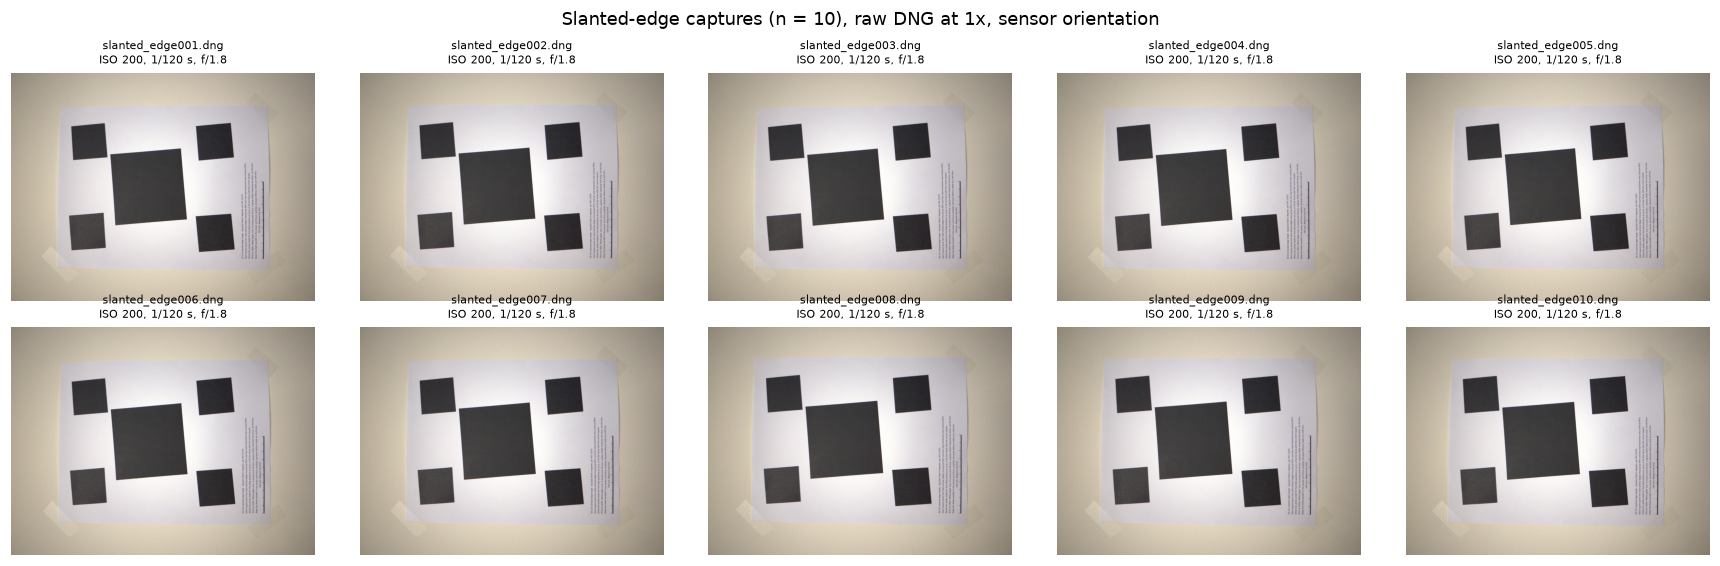

In [24]:
n = len(edge_files)
cols = 5
rows_ = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows_, cols, figsize=(3.2 * cols, 2.6 * rows_))
for ax, f in zip(axes.ravel(), edge_files):
    e = read_exif(f)
    ax.imshow(load_preview(f)); ax.set_title(f"{f.name}\nISO {e['iso']:.0f}, 1/{1 / e['exposure_s']:.0f} s, f/{e['N']:.1f}", fontsize=7.5); ax.axis("off")
for ax in axes.ravel()[n:]:
    ax.axis("off")
fig.suptitle(f"Slanted-edge captures (n = {n}), raw DNG at 1x, sensor orientation")
fig.tight_layout(); fig.savefig(OUT_DIR / "item12_contact_sheet.png", bbox_inches="tight"); plt.show()

## Item 13 · Same-camera check 

**Task.** Confirm with the `lens_id` assertion from the Project 1 page that every capture came from the same camera.

**Deliverable.** Assertion passing

In [25]:
def lens_id(path):
    e = read_exif(path)
    return (e["make"], e["model"], e["lens_model"], round(e["f_mm"], 3), round(e["N"], 2))

ids = {f.name: lens_id(f) for f in edge_files}
for name, i in ids.items():
    print(name, i)
assert len(set(ids.values())) == 1, f"Captures from more than one camera: {set(ids.values())}"
print(f"All {len(ids)} slanted-edge captures share one lens_id")
cal_ids = {lens_id(f) for f in calib_files}
print(f"   and the {len(calib_files)} calibration captures share it too: {cal_ids == set(ids.values())}")

slanted_edge001.dng ('Apple', 'iPhone 17 Pro Max', 'iPhone 17 Pro Max back camera 6.765mm f/1.78', 6.765, 1.8)
slanted_edge002.dng ('Apple', 'iPhone 17 Pro Max', 'iPhone 17 Pro Max back camera 6.765mm f/1.78', 6.765, 1.8)
slanted_edge003.dng ('Apple', 'iPhone 17 Pro Max', 'iPhone 17 Pro Max back camera 6.765mm f/1.78', 6.765, 1.8)
slanted_edge004.dng ('Apple', 'iPhone 17 Pro Max', 'iPhone 17 Pro Max back camera 6.765mm f/1.78', 6.765, 1.8)
slanted_edge005.dng ('Apple', 'iPhone 17 Pro Max', 'iPhone 17 Pro Max back camera 6.765mm f/1.78', 6.765, 1.8)
slanted_edge006.dng ('Apple', 'iPhone 17 Pro Max', 'iPhone 17 Pro Max back camera 6.765mm f/1.78', 6.765, 1.8)
slanted_edge007.dng ('Apple', 'iPhone 17 Pro Max', 'iPhone 17 Pro Max back camera 6.765mm f/1.78', 6.765, 1.8)
slanted_edge008.dng ('Apple', 'iPhone 17 Pro Max', 'iPhone 17 Pro Max back camera 6.765mm f/1.78', 6.765, 1.8)
slanted_edge009.dng ('Apple', 'iPhone 17 Pro Max', 'iPhone 17 Pro Max back camera 6.765mm f/1.78', 6.765, 1.8)
s

> **Answer**
>
> Assertion passed

## Item 14 · Extract one green plane, black-subtracted

**Deliverable.** One extracted green plane displayed, and which green plane and black level were used.

CFA layout     : [['B', 'G'], ['G', 'R']]
Green site used: row 0, col 1 of the 2×2 tile
Black level    : 528 DN   White level: 4095 DN   (12-bit)
Plane size     : 2016 × 1512 (sampled at 2p)
Range after normalisation: 0.0036 … 0.3302


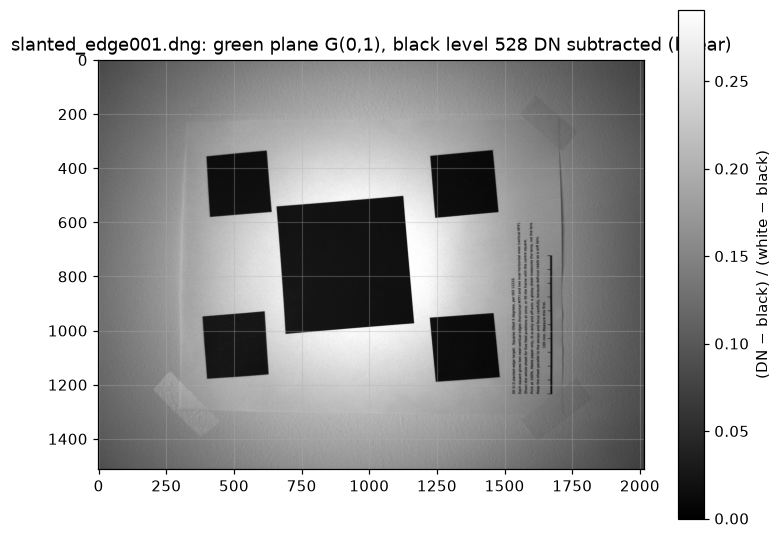

In [26]:
GREEN_WHICH = 0  

g0, ginfo = green_plane(edge_files[0], which=GREEN_WHICH)
print(f"CFA layout     : {ginfo['layout']}")
print(f"Green site used: row {ginfo['site'][0]}, col {ginfo['site'][1]} of the 2×2 tile")
print(f"Black level    : {ginfo['black']:.0f} DN   White level: {ginfo['white']:.0f} DN   (12-bit)")
print(f"Plane size     : {ginfo['shape'][1]} × {ginfo['shape'][0]} (sampled at 2p)")
print(f"Range after normalisation: {g0.min():.4f} … {g0.max():.4f}")

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(g0, cmap="gray", vmin=0, vmax=np.percentile(g0, 99.5))
ax.set_title(f"{edge_files[0].name}: green plane G(0,1), black level {ginfo['black']:.0f} DN subtracted (linear)")
fig.colorbar(im, ax=ax, label="(DN − black) / (white − black)")
fig.savefig(OUT_DIR / "item14_green_plane.png", bbox_inches="tight"); plt.show()

> **Answer**
>
> As we also saw in the first assignment the CFA tile is **BGGR**. I used the **green site at (row 0, col 1) Black level: 528 DN  I normalized it with this value $(\text{DN} - 528)/(4095 - 528)$. The brightest white reaches about 0.33 of full scale, so nothing is clipped.

## Item 15 · MTF50 on the central square, every capture

**Task.** Measure MTF50 on the central square of the target in each of your captures, and report the mean and standard deviation across them.

**Deliverable.** MTF50 as mean ± std in cycles/µm and in cycles per green-plane pixel.

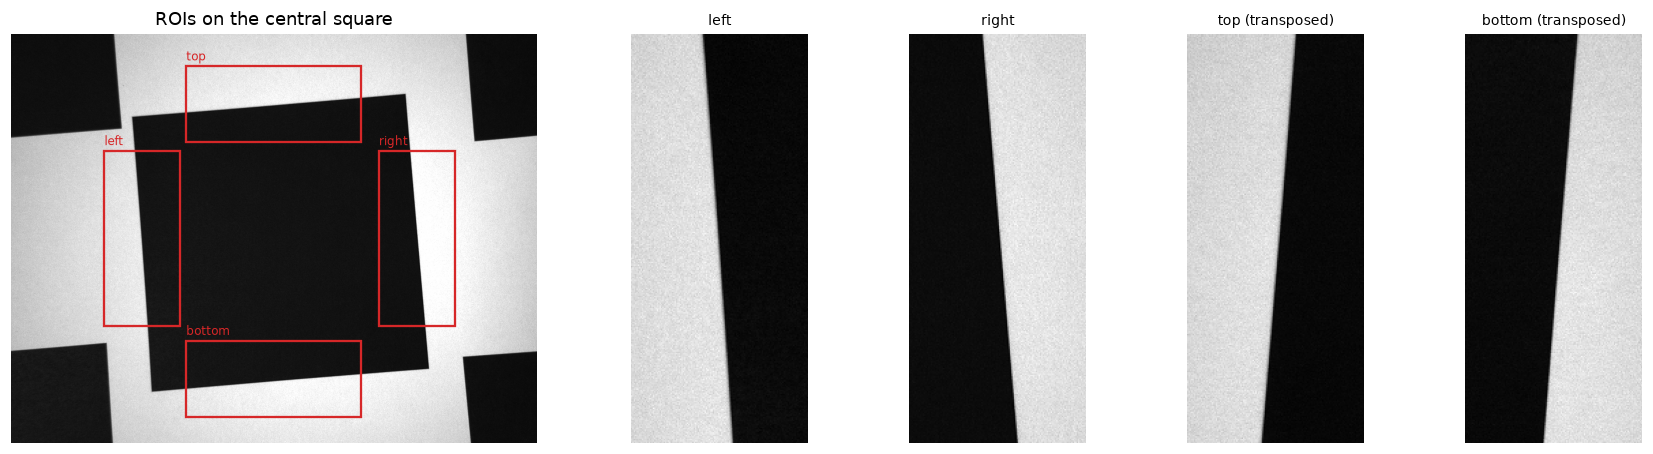

In [27]:
ROIS = {
    "left":   (600,  610, 300, 130, False),   
    "right":  (600, 1080, 300, 130, False),
    "top":    (455,  750, 130, 300, True),   
    "bottom": (925,  750, 130, 300, True),
}

def crop_roi(plane, roi):
    r0, c0, h, w, transpose = roi
    sub = plane[r0:r0 + h, c0:c0 + w]
    return sub.T if transpose else sub

fig, axes = plt.subplots(1, 5, figsize=(16, 4.2), gridspec_kw={"width_ratios": [2.2, 1, 1, 1, 1]})
axes[0].imshow(g0, cmap="gray", vmin=0, vmax=np.percentile(g0, 99.5))
for name, (r0, c0, h, w, _) in ROIS.items():
    axes[0].add_patch(plt.Rectangle((c0, r0), w, h, fill=False, ec="tab:red", lw=1.5))
    axes[0].text(c0, r0 - 10, name, color="tab:red", fontsize=8)
axes[0].set_xlim(450, 1350); axes[0].set_ylim(1100, 400); axes[0].set_title("ROIs on the central square"); axes[0].axis("off")
for ax, (name, roi) in zip(axes[1:], ROIS.items()):
    ax.imshow(crop_roi(g0, roi), cmap="gray"); ax.set_title(f"{name}{' (transposed)' if roi[4] else ''}", fontsize=9); ax.axis("off")
fig.tight_layout(); fig.savefig(OUT_DIR / "item15_rois.png", bbox_inches="tight"); plt.show()

In [28]:
per_edge = {name: [] for name in ROIS}     
for f in edge_files:
    g, _ = green_plane(f, which=GREEN_WHICH)
    for name, roi in ROIS.items():
        res = slanted_edge_mtf(crop_roi(g, roi))
        per_edge[name].append({"file": f.name, "res": res, "angle_deg": res["angle_deg"],
                               "mtf50_cpx": mtf50_from_curve(res["freq"], res["mtf"])})

edge_m50 = {name: np.array([r["mtf50_cpx"] for r in lst]) for name, lst in per_edge.items()}
m50_cpx  = np.mean([edge_m50[n] for n in ROIS], axis=0)          
m50_cpum = m50_cpx / (2 * P_UM)

hdr = "".join(f"{n:>9s}" for n in ROIS)
print(f"MTF50 in cycles per green-plane pixel\n{'capture':22s}{hdr}{'mean':>9s}{'(cyc/µm)':>10s}")
for i, f in enumerate(edge_files):
    print(f"{f.name:22s}" + "".join(f"{edge_m50[n][i]:9.4f}" for n in ROIS) + f"{m50_cpx[i]:9.4f}{m50_cpum[i]:10.4f}")
print("-" * 80)
print(f"{'mean ± std':22s}" + "".join(f"{edge_m50[n].mean():9.4f}" for n in ROIS) + f"{m50_cpx.mean():9.4f}{m50_cpum.mean():10.4f}")
print(f"{'':22s}" + "".join(f"{edge_m50[n].std(ddof=1):9.4f}" for n in ROIS) + f"{m50_cpx.std(ddof=1):9.4f}{m50_cpum.std(ddof=1):10.4f}")

print(f"\nCentral-square MTF50 (n = {len(m50_cpx)} captures, mean of 4 edges, sample std):")
print(f"   {m50_cpx.mean():.4f} ± {m50_cpx.std(ddof=1):.4f} cycles / green-plane px")
print(f"   {m50_cpum.mean():.4f} ± {m50_cpum.std(ddof=1):.4f} cycles / µm   ({m50_cpum.mean() * 1000:.1f} ± {m50_cpum.std(ddof=1) * 1000:.1f} cyc/mm)")
print(f"   coefficient of variation {100 * m50_cpx.std(ddof=1) / m50_cpx.mean():.2f} %")
angles = np.array([r["angle_deg"] for r in per_edge["left"]])


results = [{"file": f.name, "edges": {n: per_edge[n][i]["res"] for n in ROIS}} for i, f in enumerate(edge_files)]

MTF50 in cycles per green-plane pixel
capture                    left    right      top   bottom     mean  (cyc/µm)
slanted_edge001.dng      0.2464   0.4632   0.2481   0.3365   0.3235    0.0668
slanted_edge002.dng      0.2263   0.3659   0.2348   0.2815   0.2771    0.0572
slanted_edge003.dng      0.2411   0.4364   0.2352   0.3002   0.3032    0.0626
slanted_edge004.dng      0.2411   0.3935   0.2341   0.2990   0.2919    0.0603
slanted_edge005.dng      0.2461   0.3950   0.2340   0.2831   0.2896    0.0598
slanted_edge006.dng      0.2423   0.4002   0.2647   0.2945   0.3004    0.0620
slanted_edge007.dng      0.2231   0.3886   0.2161   0.2965   0.2811    0.0580
slanted_edge008.dng      0.2161   0.3739   0.2280   0.2613   0.2698    0.0557
slanted_edge009.dng      0.2114   0.3733   0.2193   0.2695   0.2684    0.0554
slanted_edge010.dng      0.2183   0.3924   0.2752   0.3326   0.3046    0.0629
--------------------------------------------------------------------------------
mean ± std             

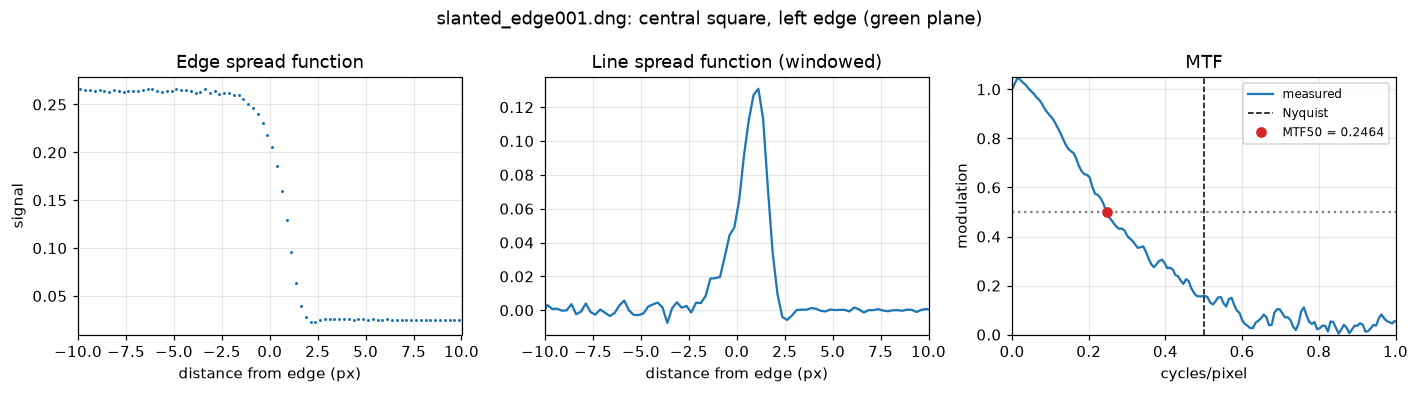

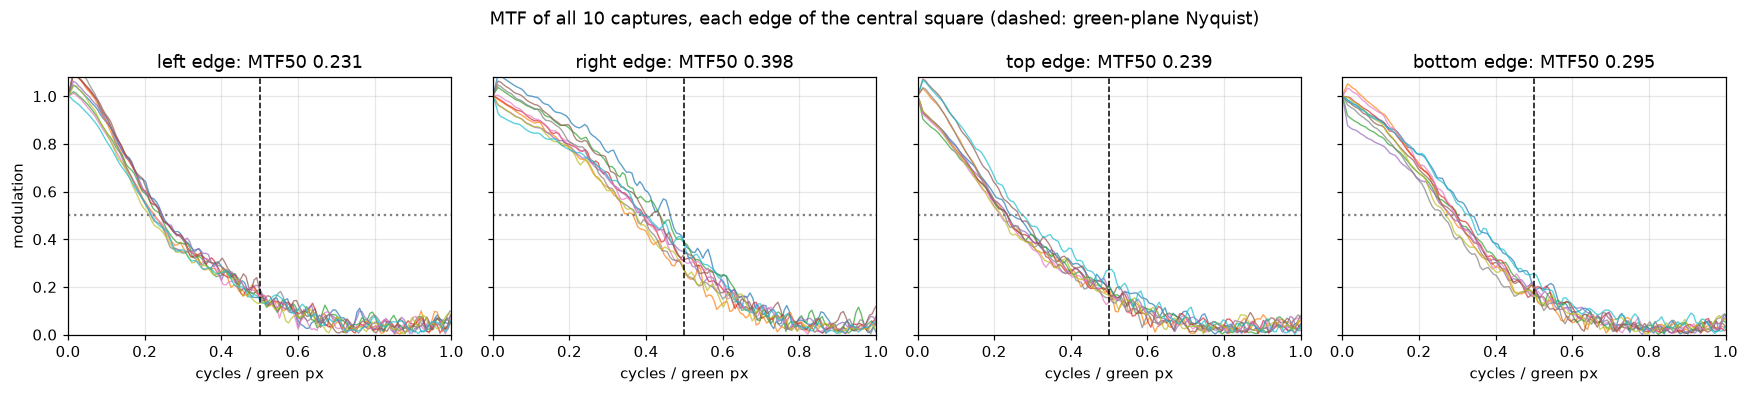

In [29]:
plot_esf_lsf_mtf(per_edge["left"][0]["res"], f"{edge_files[0].name}: central square, left edge (green plane)",
                 xlim_px=10, save=OUT_DIR / "item15_esf_lsf_mtf_capture1.png")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, name in zip(axes, ROIS):
    for r in per_edge[name]:
        ax.plot(r["res"]["freq"], r["res"]["mtf"], lw=0.9, alpha=0.7)
    ax.axhline(0.5, ls=":", c="gray"); ax.axvline(0.5, ls="--", c="k", lw=1)
    ax.set(xlim=(0, 1.0), ylim=(0, 1.08), xlabel="cycles / green px", title=f"{name} edge: MTF50 {edge_m50[name].mean():.3f}")
axes[0].set_ylabel("modulation")
fig.suptitle(f"MTF of all {len(edge_files)} captures, each edge of the central square (dashed: green-plane Nyquist)")
fig.tight_layout(); fig.savefig(OUT_DIR / "item15_all_mtf.png", bbox_inches="tight"); plt.show()

In [30]:
g1, _ = green_plane(edge_files[0], which=GREEN_WHICH)
white = g1[600:900, 615:645]; black = g1[600:900, 712:742]           
sw = np.std(np.diff(white, axis=1)) / np.sqrt(2); sb = np.std(np.diff(black, axis=1)) / np.sqrt(2)   
a_shot = (sw**2 - sb**2) / (white.mean() - black.mean()); b_read = sb**2 - a_shot * black.mean()
print(f"white {white.mean():.4f} ± {sw:.4f}, black {black.mean():.4f} ± {sb:.4f}  →  var = {a_shot:.2e}·I + {b_read:.2e}")

sigma_eq = analytic_mtf50(1.0) / m50_cpx.mean()                  
sim_m50 = np.array([mtf50_from_curve(**{k: v for k, v in slanted_edge_mtf(
            synthetic_edge(h=300, w=130, angle_deg=4.3, sigma=sigma_eq, lo=black.mean(), hi=white.mean(),
                           shot=(a_shot, b_read), seed=s)).items() if k in ("freq", "mtf")}) for s in range(40)])
cv_noise = 100 * sim_m50.std(ddof=1) / sim_m50.mean()
cv_obs_edge = np.mean([100 * edge_m50[n].std(ddof=1) / edge_m50[n].mean() for n in ROIS])
print(f"Simulated single-edge MTF50 scatter from noise alone (σ_eq = {sigma_eq:.2f} px, 40 seeds): CV = {cv_noise:.1f} %")
print(f"Observed single-edge MTF50 scatter across captures (mean over the 4 edges):     CV = {cv_obs_edge:.1f} %")
print(f"Expected CV of the 4-edge mean from noise alone ≈ {cv_noise / 2:.1f} %;  observed {100 * m50_cpx.std(ddof=1) / m50_cpx.mean():.1f} %")

white 0.2589 ± 0.0082, black 0.0246 ± 0.0027  →  var = 2.55e-04·I + 9.34e-07
Simulated single-edge MTF50 scatter from noise alone (σ_eq = 0.64 px, 40 seeds): CV = 5.7 %
Observed single-edge MTF50 scatter across captures (mean over the 4 edges):     CV = 7.4 %
Expected CV of the 4-edge mean from noise alone ≈ 2.8 %;  observed 6.0 %


> **Answer**
>
> **Central-square MTF50:**
>
> - **0.291 ± 0.017 cycles per green-plane pixel**
> - **0.0601 ± 0.0036 cycles/µm**


## Item 16 · Prediction vs measurement at Nyquist

**Task.** Compare your measurement against your prediction by reporting the predicted modulation at the Nyquist frequency from item 7 alongside the measured value at the same frequency. The prediction accounted for diffraction and the photodiode aperture only. Identify the effects present in the real system that it omitted, state which one you believe dominates, and describe a measurement that would distinguish between them.

**Deliverable.** Predicted and measured modulation at Nyquist,

Predicted modulation at green Nyquist (0.1032 cyc/µm = 0.5 cyc/green px): 0.7834
Measured  modulation at green Nyquist, central square (mean of 4 edges): 0.2160 ± 0.0249
   left    edge: 0.1666 ± 0.0194
   right   edge: 0.3262 ± 0.0477
   top     edge: 0.1804 ± 0.0379
   bottom  edge: 0.1908 ± 0.0277
Measured / predicted at Nyquist: 0.276
MTF50 measured 0.0601 cyc/µm vs predicted 0.1974 cyc/µm (ratio 0.304)


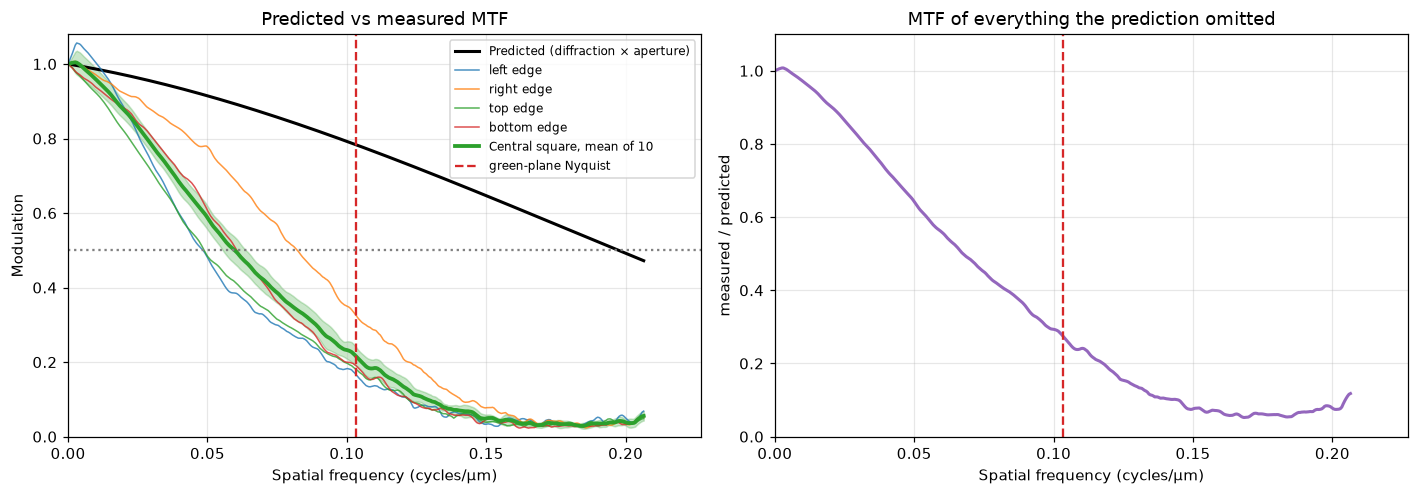

In [31]:
pred = json.loads((OUT_DIR / "predictions_frozen.json").read_text())

f_gpx = np.linspace(0, 1.0, 401)
curves = {n: np.array([np.interp(f_gpx, r["res"]["freq"], r["res"]["mtf"]) for r in per_edge[n]]) for n in ROIS}
square_curves = np.mean([curves[n] for n in ROIS], axis=0)        
mtf_nyq_meas = np.array([np.interp(0.5, f_gpx, c) for c in square_curves])

print(f"Predicted modulation at green Nyquist ({pred['nu_nyq_green_cyc_per_um']:.4f} cyc/µm = 0.5 cyc/green px): {pred['mtf_at_nyq_pred']:.4f}")
print(f"Measured  modulation at green Nyquist, central square (mean of 4 edges): {mtf_nyq_meas.mean():.4f} ± {mtf_nyq_meas.std(ddof=1):.4f}")
for n in ROIS:
    v = np.array([np.interp(0.5, f_gpx, c) for c in curves[n]])
    print(f"   {n:7s} edge: {v.mean():.4f} ± {v.std(ddof=1):.4f}")
print(f"Measured / predicted at Nyquist: {mtf_nyq_meas.mean() / pred['mtf_at_nyq_pred']:.3f}")
print(f"MTF50 measured {m50_cpum.mean():.4f} cyc/µm vs predicted {pred['mtf50_pred_cyc_per_um']:.4f} cyc/µm "
      f"(ratio {m50_cpum.mean() / pred['mtf50_pred_cyc_per_um']:.3f})")

f_um = f_gpx / (2 * pred["p_um"])
meas_mean, meas_std = square_curves.mean(0), square_curves.std(0, ddof=1)
pred_curve = mtf_pred(f_um, pred["nu_c_cyc_per_um"], pred["p_um"])
xmax = 2.2 * pred["nu_nyq_green_cyc_per_um"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
ax.plot(f_um, pred_curve, "k-", lw=2, label="Predicted (diffraction × aperture)")
for n in ROIS:
    ax.plot(f_um, curves[n].mean(0), lw=1, alpha=0.8, label=f"{n} edge")
ax.plot(f_um, meas_mean, c="tab:green", lw=2.5, label=f"Central square, mean of {len(edge_files)}")
ax.fill_between(f_um, meas_mean - meas_std, meas_mean + meas_std, color="tab:green", alpha=0.25)
ax.axvline(pred["nu_nyq_green_cyc_per_um"], ls="--", c="tab:red", label="green-plane Nyquist")
ax.axhline(0.5, ls=":", c="gray")
ax.set(xlim=(0, xmax), ylim=(0, 1.08), xlabel="Spatial frequency (cycles/µm)", ylabel="Modulation", title="Predicted vs measured MTF")
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(f_um, meas_mean / np.maximum(pred_curve, 1e-6), c="tab:purple", lw=2)
ax.axvline(pred["nu_nyq_green_cyc_per_um"], ls="--", c="tab:red")
ax.set(xlim=(0, xmax), ylim=(0, 1.1), xlabel="Spatial frequency (cycles/µm)", ylabel="measured / predicted",
       title="MTF of everything the prediction omitted")
fig.tight_layout(); fig.savefig(OUT_DIR / "item16_pred_vs_meas.png", bbox_inches="tight"); plt.show()

> **Answer item 16**
>
> **Predicted modulation at green-plane Nyquist: 0.783. Measured: 0.216 ± 0.025** Prediction seems to omit optical aberrations, defocus, camera motion. I think based on these results that the lensa aberrations comined with focus error dominate because the four edges of one central square differ by 1.7× in MTF50, whereas crosstalk and diffraction act the same everywhere in such a small central patch and motion would soften the left and right edges equally. Repeating the capture on a tripod would correct the motion, also more tests using the red and blue planes could help to understand the chromatic aberration.



# Part 5 · Reflections

## Item 17 · What did you learn from this assignment?

> It is usually difficult to compare measurements with a simulated answer and in this case I learned about this setup for simulation of the slanted edge and gave me a few ideas with some experiments in my research. i also learned how fragile inputs like the pixel pitch or the EXIF route can be. Finally, I realized that at f/1.8 neither diffraction nor the pixel aperture limits this camera (iphone camera); lens aberration and focus do.

## Item 18 · Questions for the instructor

> 1. Is it acceptable to use the EXIF route when the calibration route is shown to be biased by focus breathing, or should the calibration value be corrected and used instead?
> 3. These 12 MP Bayer raws come from a 48 MP sensor. Does binning change how the aperture should be modelled?